<a href="https://colab.research.google.com/github/brotheramin/MachineLearning/blob/main/waterReservoirePollution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Reading dataset: Water_Quality_Dataset.csv

DATASET OVERVIEW
----------------
Rows after cleaning: 1000
Date range: 2024-01-01 00:00:00 to 2024-02-11 15:00:00
Training rows: 800 | Test rows: 200

Overall class counts:
Pollution_Level
0      6
1     79
2    915
Name: count, dtype: int64

Training class counts:
Pollution_Level
0      5
1     61
2    734
Name: count, dtype: int64

Test class counts:
Pollution_Level
0      1
1     18
2    181
Name: count, dtype: int64

CLASS IMBALANCE CHECK
Pollution_Level
0      6
1     79
2    915


Training Random Forest...

RANDOM FOREST RESULTS
Accuracy:           0.9550
Balanced accuracy:  0.5185
Weighted precision: 0.9485
Weighted recall:    0.9550
Weighted F1:        0.9475

Classification report:
              precision    recall  f1-score   support

    Good (0)       0.00      0.00      0.00         1
Moderate (1)       0.91      0.56      0.69        18
Polluted (2)       0.96      1.00      0.98       181

    accuracy                         

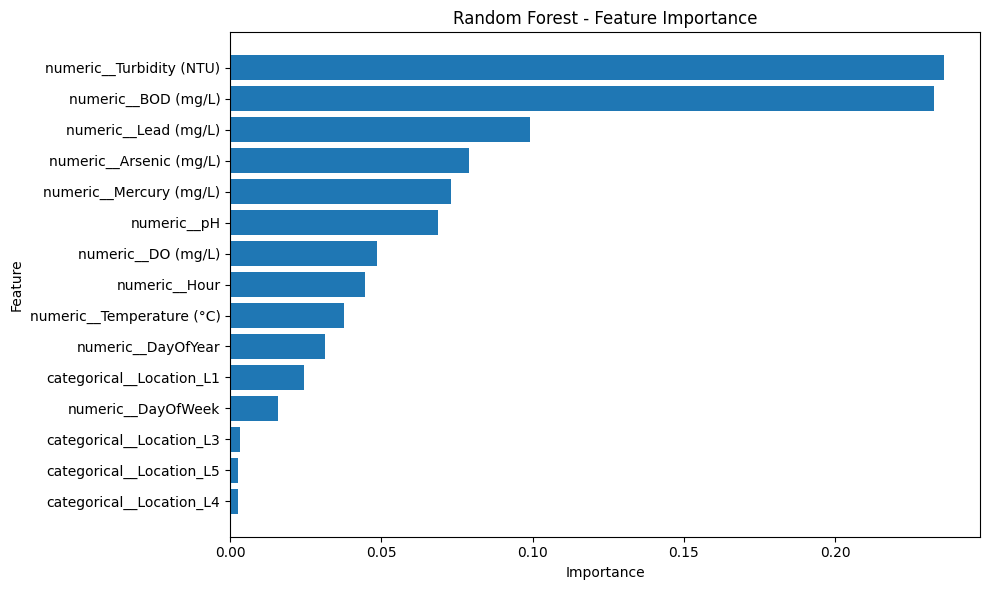

ImportError: pgmpy is required for the Bayesian Network. In Google Colab run:
!pip install -U pgmpy
Then restart the runtime and run all cells again.

In [ ]:
"""\
Water Quality Pollution Classification
Models: Random Forest + Discrete Bayesian Network

Google Colab:
    1. Upload this script and Water_Quality_Dataset.csv, or paste this file's
       contents into a notebook cell / save it as a .py file.
    2. Install dependencies in a cell:
           !pip install -U pandas numpy matplotlib scikit-learn pgmpy
    3. If running as a script:
           !python /content/water_quality_ml_fixed.py

Local Python:
    pip install -U pandas numpy matplotlib scikit-learn pgmpy
    python water_quality_ml_fixed.py

The script looks for Water_Quality_Dataset.csv in the current directory,
then /content (Google Colab). It uses a chronological 80/20 split.
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# ---------------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------------

DATA_FILENAME = "Water_Quality_Dataset.csv"
TARGET = "Pollution_Level"
TEST_SIZE = 0.20
RANDOM_STATE = 42
CLASS_LABELS = [0, 1, 2]
CLASS_NAMES = ["Good (0)", "Moderate (1)", "Polluted (2)"]

REQUIRED_COLUMNS = [
    "Timestamp",
    "Location",
    "pH",
    "Turbidity (NTU)",
    "Temperature (°C)",
    "DO (mg/L)",
    "BOD (mg/L)",
    "Lead (mg/L)",
    "Mercury (mg/L)",
    "Arsenic (mg/L)",
    TARGET,
]


def find_data_file():
    """Find the CSV in common local and Google Colab locations."""
    candidates = [
        Path(DATA_FILENAME),
        Path.cwd() / DATA_FILENAME,
        Path("/content") / DATA_FILENAME,
    ]
    for path in candidates:
        if path.exists():
            return path

    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. In Google Colab, run:\n"
        "from google.colab import files\n"
        "files.upload()\n"
        "Then upload Water_Quality_Dataset.csv and run the script again."
    )


def load_and_prepare_data():
    data_path = find_data_file()
    print(f"Reading dataset: {data_path}")
    data = pd.read_csv(data_path)

    missing_columns = sorted(set(REQUIRED_COLUMNS) - set(data.columns))
    if missing_columns:
        raise ValueError(f"The CSV is missing these columns: {missing_columns}")

    # Parse and clean timestamps / target values.
    data["Timestamp"] = pd.to_datetime(data["Timestamp"], errors="coerce")
    data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
    data = data.dropna(subset=["Timestamp", TARGET]).copy()
    data[TARGET] = data[TARGET].astype(int)
    data = data.drop_duplicates().sort_values("Timestamp").reset_index(drop=True)

    unexpected = sorted(set(data[TARGET].unique()) - set(CLASS_LABELS))
    if unexpected:
        raise ValueError(
            f"Unexpected values in {TARGET}: {unexpected}. "
            f"Expected only {CLASS_LABELS}."
        )

    # Create time features; raw Timestamp is not used directly as a predictor.
    data["Hour"] = data["Timestamp"].dt.hour
    data["DayOfWeek"] = data["Timestamp"].dt.dayofweek
    data["DayOfYear"] = data["Timestamp"].dt.dayofyear

    feature_columns = [
        "Location",
        "pH",
        "Turbidity (NTU)",
        "Temperature (°C)",
        "DO (mg/L)",
        "BOD (mg/L)",
        "Lead (mg/L)",
        "Mercury (mg/L)",
        "Arsenic (mg/L)",
        "Hour",
        "DayOfWeek",
        "DayOfYear",
    ]

    X = data[feature_columns].copy()
    y = data[TARGET].copy()

    # Chronological holdout: train on earlier observations, test on later ones.
    split_index = int(len(data) * (1 - TEST_SIZE))
    if split_index <= 0 or split_index >= len(data):
        raise ValueError("Not enough rows to create the requested train/test split.")

    X_train = X.iloc[:split_index].copy()
    X_test = X.iloc[split_index:].copy()
    y_train = y.iloc[:split_index].copy()
    y_test = y.iloc[split_index:].copy()

    if y_train.nunique() < 2:
        raise ValueError("The training portion contains fewer than two target classes.")

    print("\nDATASET OVERVIEW")
    print("----------------")
    print(f"Rows after cleaning: {len(data)}")
    print(f"Date range: {data['Timestamp'].min()} to {data['Timestamp'].max()}")
    print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
    print("\nOverall class counts:")
    print(y.value_counts().sort_index().reindex(CLASS_LABELS, fill_value=0))
    print("\nTraining class counts:")
    print(y_train.value_counts().sort_index().reindex(CLASS_LABELS, fill_value=0))
    print("\nTest class counts:")
    print(y_test.value_counts().sort_index().reindex(CLASS_LABELS, fill_value=0))

    return data, X_train, X_test, y_train, y_test, feature_columns


def print_metrics(model_name, y_true, y_pred, y_prob, model_classes):
    """Print consistent classification metrics for either model."""
    print(f"\n{model_name} RESULTS")
    print("=" * 65)
    print(f"Accuracy:           {accuracy_score(y_true, y_pred):.4f}")
    print(f"Balanced accuracy:  {balanced_accuracy_score(y_true, y_pred):.4f}")
    print(
        "Weighted precision: "
        f"{precision_score(y_true, y_pred, average='weighted', zero_division=0):.4f}"
    )
    print(
        "Weighted recall:    "
        f"{recall_score(y_true, y_pred, average='weighted', zero_division=0):.4f}"
    )
    print(
        "Weighted F1:        "
        f"{f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}"
    )

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=CLASS_LABELS,
            target_names=CLASS_NAMES,
            zero_division=0,
        )
    )

    # Align probability columns with class labels [0, 1, 2].
    aligned_probabilities = np.zeros((len(y_prob), len(CLASS_LABELS)), dtype=float)
    for column_index, class_value in enumerate(model_classes):
        if int(class_value) in CLASS_LABELS:
            aligned_probabilities[:, CLASS_LABELS.index(int(class_value))] = y_prob[:, column_index]

    present_test_classes = set(pd.Series(y_true).astype(int).unique())
    if present_test_classes == set(CLASS_LABELS):
        try:
            auc = roc_auc_score(
                np.asarray(y_true, dtype=int),
                aligned_probabilities,
                labels=CLASS_LABELS,
                multi_class="ovr",
                average="weighted",
            )
            print(f"Weighted OVR ROC-AUC: {auc:.4f}")
        except ValueError as exc:
            print(f"ROC-AUC unavailable for this split: {exc}")
    else:
        missing = sorted(set(CLASS_LABELS) - present_test_classes)
        print(f"ROC-AUC not calculated: test set is missing class(es) {missing}.")


def train_random_forest(X_train, X_test, y_train, y_test):
    categorical_features = ["Location"]
    numeric_features = [c for c in X_train.columns if c not in categorical_features]

    numeric_pipeline = Pipeline(
        [("imputer", SimpleImputer(strategy="median"))]
    )
    categorical_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    preprocessing = ColumnTransformer(
        [
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ]
    )

    model = Pipeline(
        [
            ("preprocessing", preprocessing),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=500,
                    min_samples_leaf=2,
                    class_weight="balanced_subsample",
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]
    )

    print("\nTraining Random Forest...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)
    classes = model.named_steps["classifier"].classes_

    print_metrics("RANDOM FOREST", y_test, predictions, probabilities, classes)

    feature_names = model.named_steps["preprocessing"].get_feature_names_out()
    feature_values = model.named_steps["classifier"].feature_importances_
    importance = (
        pd.DataFrame({"Feature": feature_names, "Importance": feature_values})
        .sort_values("Importance", ascending=False)
        .reset_index(drop=True)
    )
    print("\nTop 15 Random Forest feature importances:")
    print(importance.head(15).to_string(index=False))

    top_importance = importance.head(15).iloc[::-1]
    plt.figure(figsize=(10, 6))
    plt.barh(top_importance["Feature"], top_importance["Importance"])
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title("Random Forest - Feature Importance")
    plt.tight_layout()
    plt.savefig("random_forest_feature_importance.png", dpi=200)
    plt.show()

    return model, predictions, probabilities, classes, importance


def discretize_for_bayesian_network(X_train, X_test):
    """Discretize numeric predictors using training data only."""
    train_discrete = pd.DataFrame(index=X_train.index)
    test_discrete = pd.DataFrame(index=X_test.index)

    numeric_columns = X_train.select_dtypes(include=[np.number]).columns.tolist()
    categorical_columns = [c for c in X_train.columns if c not in numeric_columns]

    for column in numeric_columns:
        train_values = pd.to_numeric(X_train[column], errors="coerce")
        test_values = pd.to_numeric(X_test[column], errors="coerce")

        median_value = train_values.median()
        if pd.isna(median_value):
            median_value = 0.0
        train_values = train_values.fillna(median_value)
        test_values = test_values.fillna(median_value)

        quantiles = np.unique(
            train_values.quantile([0.0, 0.25, 0.50, 0.75, 1.0]).to_numpy(dtype=float)
        )

        if len(quantiles) < 2:
            train_discrete[column] = "bin_0"
            test_discrete[column] = "bin_0"
        else:
            edges = quantiles.copy()
            edges[0] = -np.inf
            edges[-1] = np.inf

            train_bins = pd.cut(
                train_values, bins=edges, labels=False, include_lowest=True
            )
            test_bins = pd.cut(
                test_values, bins=edges, labels=False, include_lowest=True
            )

            train_discrete[column] = train_bins.fillna(0).astype(int).map(
                lambda value: f"bin_{value}"
            )
            test_discrete[column] = test_bins.fillna(0).astype(int).map(
                lambda value: f"bin_{value}"
            )

    for column in categorical_columns:
        train_values = X_train[column].fillna("Unknown").astype(str)
        test_values = X_test[column].fillna("Unknown").astype(str)

        # Map test-only categories to a category observed during training.
        known_values = set(train_values.unique())
        fallback_value = train_values.mode().iloc[0] if not train_values.mode().empty else "Unknown"
        test_values = test_values.where(test_values.isin(known_values), fallback_value)

        train_discrete[column] = train_values
        test_discrete[column] = test_values

    # pgmpy expects discrete state values; strings keep all variables consistent.
    for column in train_discrete.columns:
        train_discrete[column] = train_discrete[column].astype(str)
        test_discrete[column] = test_discrete[column].astype(str)

    return train_discrete, test_discrete


def learn_bayesian_network_structure(training_data):
    """Learn a DAG, with compatibility for pgmpy API variants."""
    try:
        from pgmpy.estimators import HillClimbSearch
    except ImportError as exc:
        raise ImportError(
            "pgmpy is not installed. Run: !pip install -U pgmpy"
        ) from exc

    search = HillClimbSearch(training_data)

    # BIC is available in the pgmpy version used by current Colab installs.
    try:
        from pgmpy.estimators import BIC
        scoring_method = BIC(training_data)
    except ImportError:
        # Compatibility with older pgmpy releases.
        from pgmpy.estimators import BicScore
        scoring_method = BicScore(training_data)

    learned_dag = search.estimate(
        scoring_method=scoring_method,
        max_indegree=2,
        max_iter=500,
        show_progress=False,
    )
    return learned_dag


def train_bayesian_network(X_train, X_test, y_train, y_test):
    try:
        from pgmpy.estimators import BayesianEstimator
        from pgmpy.models import DiscreteBayesianNetwork
        from pgmpy.inference import VariableElimination
    except ImportError as exc:
        raise ImportError(
            "pgmpy is required for the Bayesian Network. In Google Colab run:\n"
            "!pip install -U pgmpy\n"
            "Then restart the runtime and run all cells again."
        ) from exc

    print("\nPreparing discrete data for Bayesian Network...")
    train_bn, test_bn = discretize_for_bayesian_network(X_train, X_test)

    bn_training_data = train_bn.copy().reset_index(drop=True)
    bn_training_data[TARGET] = y_train.astype(int).astype(str).to_numpy()

    print("Learning Bayesian Network structure...")
    learned_dag = learn_bayesian_network_structure(bn_training_data)
    print("\nLearned Bayesian Network edges:")
    print(list(learned_dag.edges()))

    # Build the network and include any isolated variables.
    bn_model = DiscreteBayesianNetwork(list(learned_dag.edges()))
    bn_model.add_nodes_from(bn_training_data.columns.tolist())

    # IMPORTANT FIX:
    # Do not pass prior_type into bn_model.fit(). In some pgmpy versions,
    # DiscreteBayesianNetwork.fit() does not accept that keyword argument.
    # Estimate CPDs directly and attach them to the model instead.
    print("Estimating Bayesian Network conditional probability tables...")
    bayesian_estimator = BayesianEstimator(bn_model, bn_training_data)
    cpds = bayesian_estimator.get_parameters(
        prior_type="BDeu",
        equivalent_sample_size=10,
    )
    bn_model.add_cpds(*cpds)

    if not bn_model.check_model():
        raise RuntimeError(
            "The Bayesian Network failed check_model(). "
            "Please share the complete error message."
        )

    print("Bayesian Network fitted and validated successfully.")
    inference = VariableElimination(bn_model)

    predictions = []
    probabilities = []
    target_states = ["0", "1", "2"]

    print("Predicting the held-out test observations...")
    for _, observation in test_bn.iterrows():
        evidence = observation.to_dict()
        query = inference.query(
            variables=[TARGET],
            evidence=evidence,
            show_progress=False,
        )

        returned_states = query.state_names[TARGET]
        returned_probabilities = np.asarray(query.values, dtype=float).reshape(-1)
        state_probability = {
            str(state): float(probability)
            for state, probability in zip(returned_states, returned_probabilities)
        }

        row_probabilities = np.array(
            [state_probability.get(state, 0.0) for state in target_states],
            dtype=float,
        )
        probability_sum = row_probabilities.sum()
        if not np.isfinite(probability_sum) or probability_sum <= 0:
            row_probabilities = np.full(len(target_states), 1.0 / len(target_states))
        else:
            row_probabilities /= probability_sum

        probabilities.append(row_probabilities)
        predictions.append(int(target_states[int(np.argmax(row_probabilities))]))

    predictions = np.asarray(predictions, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    print_metrics(
        "BAYESIAN NETWORK",
        y_test,
        predictions,
        probabilities,
        np.asarray(CLASS_LABELS),
    )

    return bn_model, predictions, probabilities


def plot_confusion_matrices(y_test, rf_predictions, bn_predictions):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for axis, predictions, title in [
        (axes[0], rf_predictions, "Random Forest"),
        (axes[1], bn_predictions, "Bayesian Network"),
    ]:
        matrix = confusion_matrix(y_test, predictions, labels=CLASS_LABELS)
        image = axis.imshow(matrix, interpolation="nearest", cmap="Blues")
        axis.figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
        axis.set(
            xticks=np.arange(len(CLASS_NAMES)),
            yticks=np.arange(len(CLASS_NAMES)),
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            title=f"{title} Confusion Matrix",
            xlabel="Predicted class",
            ylabel="Actual class",
        )
        threshold = matrix.max() / 2.0 if matrix.size else 0
        for row in range(matrix.shape[0]):
            for column in range(matrix.shape[1]):
                axis.text(
                    column, row, str(matrix[row, column]),
                    ha="center", va="center",
                    color="white" if matrix[row, column] > threshold else "black",
                )
        axis.tick_params(axis="x", rotation=25)

    plt.tight_layout()
    plt.savefig("confusion_matrices.png", dpi=200)
    plt.show()


def main():
    # Suppress only FutureWarning messages from dependencies; real errors remain visible.
    warnings.filterwarnings("ignore", category=FutureWarning, module="pgmpy")

    data, X_train, X_test, y_train, y_test, _ = load_and_prepare_data()

    class_counts = data[TARGET].value_counts().reindex(CLASS_LABELS, fill_value=0)
    print("\nCLASS IMBALANCE CHECK")
    print(class_counts.to_string())
    if class_counts.min() < 20:
        print(
            "\nWARNING: At least one class has fewer than 20 observations. "
            "Performance estimates for rare classes may be unreliable. "
            "The high overall accuracy may hide poor performance on rare classes."
        )

    rf_model, rf_predictions, rf_probabilities, rf_classes, importance = train_random_forest(
        X_train, X_test, y_train, y_test
    )

    bn_model, bn_predictions, bn_probabilities = train_bayesian_network(
        X_train, X_test, y_train, y_test
    )

    plot_confusion_matrices(y_test, rf_predictions, bn_predictions)

    # Save predictions and model interpretation outputs.
    rf_probability_columns = {}
    for class_value, class_name in zip(CLASS_LABELS, ["Good", "Moderate", "Polluted"]):
        if class_value in list(rf_classes):
            rf_probability_columns[f"RF_Probability_{class_name}"] = rf_probabilities[
                :, list(rf_classes).index(class_value)
            ]
        else:
            rf_probability_columns[f"RF_Probability_{class_name}"] = np.zeros(len(y_test))

    prediction_output = pd.DataFrame(
        {
            "Actual_Pollution_Level": y_test.to_numpy(),
            "Random_Forest_Prediction": rf_predictions,
            "Bayesian_Network_Prediction": bn_predictions,
            **rf_probability_columns,
            "BN_Probability_Good": bn_probabilities[:, 0],
            "BN_Probability_Moderate": bn_probabilities[:, 1],
            "BN_Probability_Polluted": bn_probabilities[:, 2],
        }
    )
    prediction_output.to_csv("heldout_predictions.csv", index=False)
    importance.to_csv("random_forest_feature_importance.csv", index=False)

    print("\nCompleted successfully. Saved files:")
    print("- random_forest_feature_importance.png")
    print("- confusion_matrices.png")
    print("- heldout_predictions.csv")
    print("- random_forest_feature_importance.csv")
    print("\nNote: The models are evaluated on the final 20% of the data in time order.")


if __name__ == "__main__":
    main()
